# Forelesning 22: Leapfrog-metoden for bølgelikningen

Dette notatboket hører til delkapittelet **Leapfrog-metoden for bølgelikningen** i kompendiet.
Vi implementerer og tester:

1. Leapfrog i 1D med Dirichlet-rand, inkludert Taylor-oppstarten for $U^1$.
2. CFL-stabilitet ($r = c\Delta t/\Delta x \le 1$) i 1D.
3. Leapfrog i 1D med periodisk rand.
4. Leapfrog i 2D (Dirichlet-rand), inkludert CFL-stabilitet ($r \le 1/\sqrt2$).


In [1]:

import numpy as np
import matplotlib.pyplot as plt


## 1. Leapfrog i 1D med Dirichlet-rand

Fra kompendiet:

$$U_i^{n+1} = 2U_i^n - U_i^{n-1} + r^2\big(U_{i+1}^n - 2U_i^n + U_{i-1}^n\big), \qquad r = \frac{c\Delta t}{\Delta x},$$

og oppstarten (Taylor-utvikling, ved å bruke selve PDE-en til å bytte ut $u_{tt}(x,0)$):

$$U_i^1 = U_i^0 + \Delta t\, v_0(x_i) + \tfrac12 r^2\big(U_{i+1}^0 - 2U_i^0 + U_{i-1}^0\big).$$

Her er $u_0(x) = u(x,0)$ initialutslaget og $v_0(x) = u_t(x,0)$ initialhastigheten.
Randverdiene $g_L(t) = u(0,t)$ og $g_R(t) = u(L,t)$ kan være tidsavhengige (her Dirichlet).


In [2]:

def leapfrog1d(c, L, N, dt, nsteps, u0, v0, gL=lambda t: 0.0, gR=lambda t: 0.0):
    '''Løser u_tt = c^2 u_xx på [0, L] med Dirichlet-rand gL(t), gR(t),
    initialutslag u0(x) og initialhastighet v0(x), med leapfrog-metoden.
    Returnerer (x, historikk, r) der historikk er en liste med U^n, n = 0, 1, ..., nsteps.'''
    h = L / N
    r = c * dt / h
    x = h * np.arange(N + 1)

    U0 = u0(x).astype(float)
    U0[0], U0[-1] = gL(0.0), gR(0.0)

    U1 = np.zeros_like(U0)
    U1[1:-1] = (U0[1:-1] + dt * v0(x[1:-1]) +
                0.5 * r**2 * (U0[2:] - 2 * U0[1:-1] + U0[:-2]))
    U1[0], U1[-1] = gL(dt), gR(dt)

    historikk = [U0.copy(), U1.copy()]
    Uprev, Ucur = U0, U1
    for n in range(1, nsteps):
        t_neste = (n + 1) * dt
        Unext = np.zeros_like(Ucur)
        Unext[1:-1] = (2 * Ucur[1:-1] - Uprev[1:-1] +
                       r**2 * (Ucur[2:] - 2 * Ucur[1:-1] + Ucur[:-2]))
        Unext[0], Unext[-1] = gL(t_neste), gR(t_neste)
        historikk.append(Unext.copy())
        Uprev, Ucur = Ucur, Unext
    return x, historikk, r


### Test mot en kjent løsning

Vi bruker samme teknikk som i separasjons-seksjonen i kompendiet: med $u_0(x) = \sin(k\pi x/L)$
og $v_0 = 0$ (ingen Dirichlet-rand -- begge ender er null), er den eksakte løsningen

$$u(x,t) = \cos\!\Big(\frac{k\pi c t}{L}\Big)\sin\!\Big(\frac{k\pi x}{L}\Big).$$


r = 0.9000
Maks feil over hele simuleringen: 0.005228917421709526


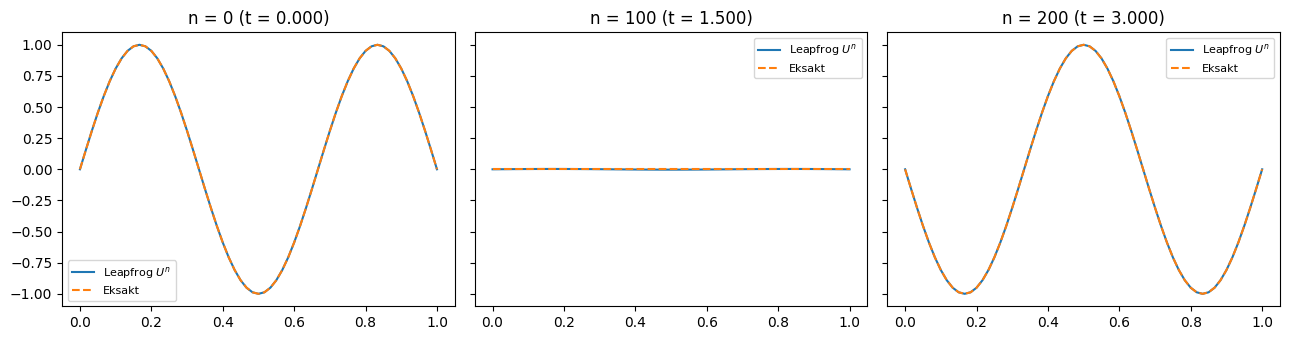

In [3]:

c, L, k = 1.0, 1.0, 3
u0 = lambda x: np.sin(k * np.pi * x / L)
v0 = lambda x: 0.0 * x
u_eksakt = lambda x, t: np.cos(k * np.pi * c * t / L) * np.sin(k * np.pi * x / L)

N = 60
h = L / N
r_valgt = 0.9
dt = r_valgt * h / c
nsteps = 200

x, hist, r = leapfrog1d(c, L, N, dt, nsteps, u0, v0)
print(f"r = {r:.4f}")

feil = [np.max(np.abs(hist[n] - u_eksakt(x, n * dt))) for n in range(nsteps + 1)]
print("Maks feil over hele simuleringen:", max(feil))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, n in zip(axs, [0, nsteps // 2, nsteps]):
    ax.plot(x, hist[n], label="Leapfrog $U^n$")
    ax.plot(x, u_eksakt(x, n * dt), "--", label="Eksakt")
    ax.set_title(f"n = {n} (t = {n*dt:.3f})")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### CFL-stabilitet: $r \le 1$

Vi gjentar med $r$ like under og like over $1$, for å illustrere stabilitetsgrensen fra
kompendiets stabilitetsboks.


In [4]:

for r_test in [1.0, 1.05]:
    dt_test = r_test * h / c
    x, hist_test, r_faktisk = leapfrog1d(c, L, N, dt_test, nsteps=150, u0=u0, v0=v0)
    maks = max(np.max(np.abs(Un)) for Un in hist_test)
    status = "stabilt" if maks < 10 else "USTABILT"
    print(f"r = {r_faktisk:.4f}: maks |U| over simuleringen = {maks:.3e}  ({status})")


r = 1.0000: maks |U| over simuleringen = 1.000e+00  (stabilt)
r = 1.0500: maks |U| over simuleringen = 2.370e+24  (USTABILT)


## 2. Leapfrog i 1D med periodisk rand

Med periodisk rand identifiserer vi $U_{-1}^n \equiv U_{N-1}^n$ og $U_N^n \equiv U_0^n$
(kompendiets formulering). Vi dropper det siste (duplikate) gridpunktet og bruker
`np.roll` til å implementere de sykliske naboene.


In [5]:

def leapfrog1d_periodisk(c, L, N, dt, nsteps, u0, v0):
    '''Løser u_tt = c^2 u_xx på [0, L) med periodisk rand, initialutslag u0(x)
    og initialhastighet v0(x), med leapfrog-metoden. Gridpunktene er x_0, ..., x_{N-1}
    (x_N = x_0 er identifisert med x_0 og tas ikke med separat).
    Returnerer (x, historikk, r).'''
    h = L / N
    r = c * dt / h
    x = h * np.arange(N)

    U0 = u0(x).astype(float)
    U0_hoyre, U0_venstre = np.roll(U0, -1), np.roll(U0, 1)
    U1 = U0 + dt * v0(x) + 0.5 * r**2 * (U0_hoyre - 2 * U0 + U0_venstre)

    historikk = [U0.copy(), U1.copy()]
    Uprev, Ucur = U0, U1
    for n in range(1, nsteps):
        Ucur_hoyre, Ucur_venstre = np.roll(Ucur, -1), np.roll(Ucur, 1)
        Unext = 2 * Ucur - Uprev + r**2 * (Ucur_hoyre - 2 * Ucur + Ucur_venstre)
        historikk.append(Unext.copy())
        Uprev, Ucur = Ucur, Unext
    return x, historikk, r


### Test: en vandrende bølge rundt sirkelen

En høyregående bølge $u(x,t) = \sin\!\big(2\pi(x-ct)/L\big)$ er periodisk med periode $L$ i $x$,
og løser bølgelikningen for enhver $c$. Vi starter med $u_0(x) = \sin(2\pi x/L)$ og
$v_0(x) = -c\,u_0'(x) = -\dfrac{2\pi c}{L}\cos(2\pi x/L)$, og sammenligner med fasiten.


r = 0.9500
Maks feil over hele simuleringen: 0.001127106370938269


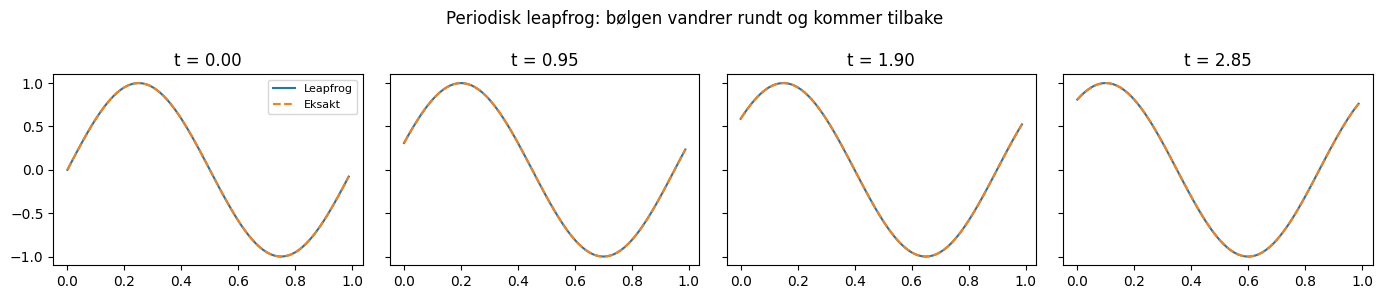

In [6]:

c, L = 1.0, 1.0
u0_p = lambda x: np.sin(2 * np.pi * x / L)
v0_p = lambda x: -c * (2 * np.pi / L) * np.cos(2 * np.pi * x / L)
u_eksakt_p = lambda x, t: np.sin(2 * np.pi * (x - c * t) / L)

N = 80
h = L / N
r_valgt = 0.95
dt = r_valgt * h / c
nsteps = 240

x, hist_p, r = leapfrog1d_periodisk(c, L, N, dt, nsteps, u0_p, v0_p)
print(f"r = {r:.4f}")

feil_p = [np.max(np.abs(hist_p[n] - u_eksakt_p(x, n * dt))) for n in range(nsteps + 1)]
print("Maks feil over hele simuleringen:", max(feil_p))

fig, axs = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, n in zip(axs, [0, 80, 160, 240]):
    ax.plot(x, hist_p[n], label="Leapfrog")
    ax.plot(x, u_eksakt_p(x, n * dt), "--", label="Eksakt")
    ax.set_title(f"t = {n*dt:.2f}")
axs[0].legend(fontsize=8)
plt.suptitle("Periodisk leapfrog: bølgen vandrer rundt og kommer tilbake")
plt.tight_layout()
plt.show()


## 3. Leapfrog i 2D

Fra kompendiet (seksjonen "To romdimensjoner"):

$$U_{i,j}^{n+1} = 2U_{i,j}^n - U_{i,j}^{n-1} +
r^2\big(U_{i+1,j}^n + U_{i-1,j}^n + U_{i,j+1}^n + U_{i,j-1}^n - 4U_{i,j}^n\big),$$

med samme type Taylor-oppstart for $U^1$, og CFL-betingelsen $r \le 1/\sqrt2 \approx 0{,}7071$
(for $\Delta x=\Delta y=h$). Her bruker vi homogen Dirichlet-rand $u=0$ (en fastspent membran).


In [7]:

def leapfrog2d(c, Lx, Ly, Nx, Ny, dt, nsteps, u0, v0):
    '''Løser u_tt = c^2 (u_xx + u_yy) på [0,Lx] x [0,Ly] med homogen Dirichlet-rand
    (u = 0 på hele randen), initialutslag u0(x,y) og initialhastighet v0(x,y),
    med leapfrog-metoden. Krever Nx == Ny (samme h i x og y).
    Returnerer (x, y, historikk, r).'''
    h = Lx / Nx
    assert abs(h - Ly / Ny) < 1e-12, "Krever kvadratiske celler (samme h i x og y)"
    r = c * dt / h
    x = h * np.arange(Nx + 1)
    y = h * np.arange(Ny + 1)
    X, Y = np.meshgrid(x, y)

    U0 = u0(X, Y).astype(float)
    U0[0, :] = U0[-1, :] = U0[:, 0] = U0[:, -1] = 0.0
    V0 = v0(X, Y)

    U1 = np.zeros_like(U0)
    U1[1:-1, 1:-1] = (U0[1:-1, 1:-1] + dt * V0[1:-1, 1:-1] +
                       0.5 * r**2 * (U0[1:-1, 2:] + U0[1:-1, :-2] +
                                     U0[2:, 1:-1] + U0[:-2, 1:-1] -
                                     4 * U0[1:-1, 1:-1]))
    U1[0, :] = U1[-1, :] = U1[:, 0] = U1[:, -1] = 0.0

    historikk = [U0.copy(), U1.copy()]
    Uprev, Ucur = U0, U1
    for n in range(1, nsteps):
        Unext = np.zeros_like(Ucur)
        Unext[1:-1, 1:-1] = (2 * Ucur[1:-1, 1:-1] - Uprev[1:-1, 1:-1] +
                              r**2 * (Ucur[1:-1, 2:] + Ucur[1:-1, :-2] +
                                      Ucur[2:, 1:-1] + Ucur[:-2, 1:-1] -
                                      4 * Ucur[1:-1, 1:-1]))
        Unext[0, :] = Unext[-1, :] = Unext[:, 0] = Unext[:, -1] = 0.0
        historikk.append(Unext.copy())
        Uprev, Ucur = Ucur, Unext
    return x, y, historikk, r


### En svingende membran

Initialutslag: en gaussisk "klokke" løftet opp midt på en fastspent kvadratisk membran,
med null initialhastighet.


r = 0.7000  (<= 1/sqrt(2) = 0.7071 kreves for stabilitet)


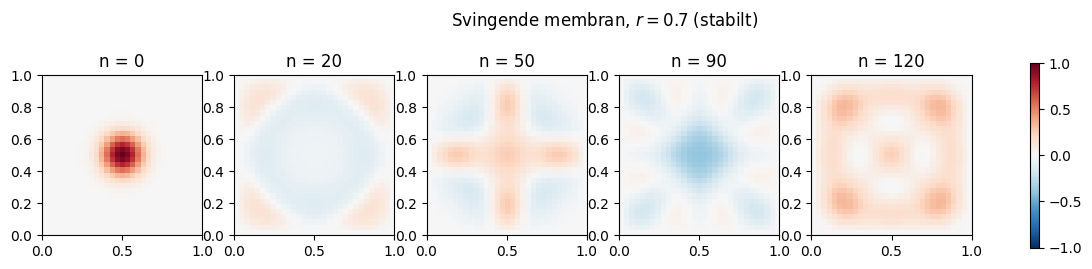

In [8]:

c = 1.0
bump2d = lambda x, y: np.exp(-60 * ((x - 0.5)**2 + (y - 0.5)**2))
null2d = lambda x, y: 0.0 * x

N = 30
h = 1.0 / N
r_stabil = 0.7            # < 1/sqrt(2) ~ 0.7071 -> stabilt
dt = r_stabil * h / c
nsteps = 120

x, y, hist2d, r = leapfrog2d(c, 1.0, 1.0, N, N, dt, nsteps, bump2d, null2d)
print(f"r = {r:.4f}  (<= 1/sqrt(2) = {1/np.sqrt(2):.4f} kreves for stabilitet)")

tider_vis = [0, 20, 50, 90, 120]
fig, axs = plt.subplots(1, len(tider_vis), figsize=(15, 3))
for ax, n in zip(axs, tider_vis):
    im = ax.imshow(hist2d[n], origin="lower", extent=[0, 1, 0, 1],
                    cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"n = {n}")
fig.colorbar(im, ax=axs, shrink=0.8)
plt.suptitle(f"Svingende membran, $r = {r_stabil}$ (stabilt)")
plt.show()


### Instabilitet når $r > 1/\sqrt2$

Vi gjentar med $r \approx 0{,}72$, like over CFL-grensen $1/\sqrt2 \approx 0{,}7071$.


r = 0.7200
Maks |U| ved n=0, 50, 100, 150: [np.float64(1.0), np.float64(0.25411518405778327), np.float64(0.2928719658857145), np.float64(2490638.008025199)]


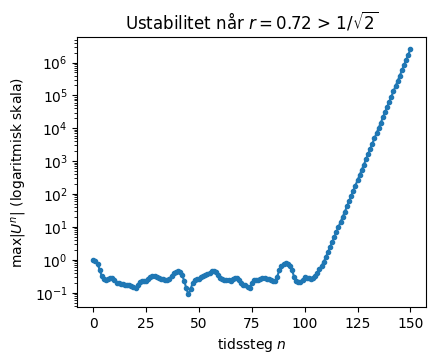

In [9]:

r_ustabil = 0.72
dt_u = r_ustabil * h / c
x, y, hist2d_u, r_u = leapfrog2d(c, 1.0, 1.0, N, N, dt_u, nsteps=150, u0=bump2d, v0=null2d)
print(f"r = {r_u:.4f}")

maxnorm = [np.max(np.abs(Un)) for Un in hist2d_u]
print("Maks |U| ved n=0, 50, 100, 150:", [maxnorm[n] for n in (0, 50, 100, 150)])

plt.figure(figsize=(4.5, 3.5))
plt.semilogy(maxnorm, marker=".")
plt.xlabel("tidssteg $n$"); plt.ylabel(r"$\max |U^n|$ (logaritmisk skala)")
plt.title(f"Ustabilitet når $r = {r_ustabil}$ > $1/\\sqrt{{2}}$")
plt.show()


## Oppsummering

* Leapfrog-metoden krever en egen oppstartsformel (Taylor-utvikling) for å finne $U^1$
  fra $u_0$ og $v_0$, siden skjemaet ellers trenger to tidligere tidsnivåer.
* CFL-betingelsen er $r = c\Delta t/\Delta x \le 1$ i 1D, og $r \le 1/\sqrt2$ i 2D
  (med $\Delta x=\Delta y=h$). Overskrides grensen, blåser løsningen opp.
* Periodisk rand implementeres enkelt med `np.roll` for de sykliske naboindeksene.
